In [1]:
%run ./dataManipulation.ipynb

In [2]:
import seaborn as sns
from scipy import stats

from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix, precision_score, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

2024-01-30 23:31:53.201199: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
columns = ['clipID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender']
listOfGenders = np.array(metadata)[:,2]
unique_values, counts = np.unique(listOfGenders, return_counts=True)

## Class Imbalance

,Value,Frequency,Percentage
Male,0,503,78.59375
Female,1,137,21.40625


Text(0.5, 1.0, 'Frequency of Classes Male vs Female')

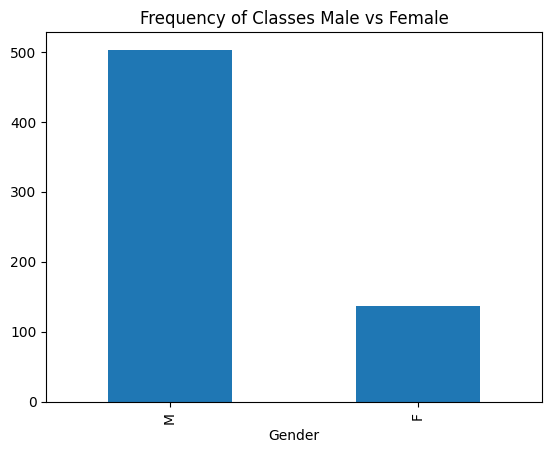

In [4]:
labelencoder=LabelEncoder()
y=to_categorical(labelencoder.fit_transform(listOfGenders))[:,0].astype(int)
# No of men vs no of women

valueCounts = pd.DataFrame(y).value_counts().reset_index()
valueCounts.columns = ['Value', 'Frequency']
valueCounts = valueCounts.rename(index={0: 'Male', 1: 'Female'})
totalClips = valueCounts['Frequency'].sum()
valueCounts['Percentage'] = (valueCounts['Frequency'] / totalClips) * 100
display(Markdown('## Class Imbalance'))
display(valueCounts)


array = np.concatenate((medianScoresPerClip(), listOfGenders.reshape(-1,1)), axis=1)
df = pd.DataFrame(array, columns=columns)
dfMale = df[df.Gender == 'M']
dfFemale = df[df.Gender == 'F']
df = pd.concat([dfMale, dfFemale])
ax = df.Gender.value_counts().plot(kind='bar')
ax.set_title('Frequency of Classes Male vs Female')

## PCA

Pricipal component variance: [0.35845079 0.29290806]
Amount of variance per principal component: [0.35845079 0.29290806 0.15350095 0.10301126 0.09212895]


<Figure size 640x480 with 0 Axes>

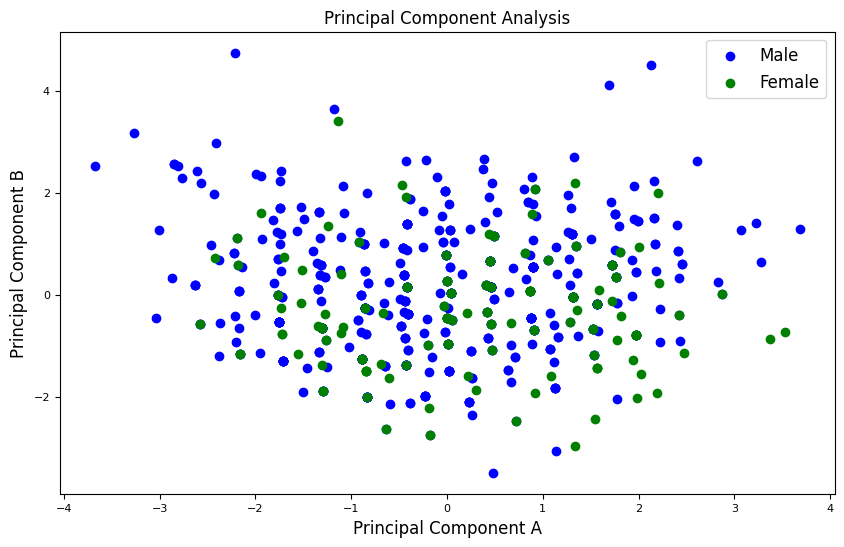

In [5]:
data = medianScoresPerClip()[:,1:]

labels = np.reshape(y, (640,1))
finalData = np.concatenate([data, labels], axis=1)
finalDataset = pd.DataFrame(finalData)
finalDataset.columns = columns[1:]
finalDataset['Gender'].replace(0, 'Male',inplace=True)
finalDataset['Gender'].replace(1, 'Female',inplace=True)

x = finalDataset.loc[:, columns[1:6]].values
x = StandardScaler().fit_transform(x)

featureCols = ['feature'+ str(i) for i in range(x.shape[1])]
normalised = pd.DataFrame(x, columns=featureCols)
# normalised.head()

pca = PCA(n_components=2)
princComp = pca.fit_transform(x)
pcaDf = pd.DataFrame(data = princComp
             , columns = ['principal component 1', 'principal component 2'])

print('Pricipal component variance: {}'.format(pca.explained_variance_ratio_))

# VARIANCE OF THE DATASET DEFINED BY EACH COMPONENT
pcaAllComponents = PCA(n_components=5)
princComp = pcaAllComponents.fit_transform(x)
print('Amount of variance per principal component: {}'.format(pcaAllComponents.explained_variance_ratio_))

# Two components result to 65% of variance while we need 4 to get 90%

plt.figure()
plt.figure(figsize=(10,6))
plt.title("Principal Component Analysis",fontsize=12)
plt.xlabel('Principal Component A',fontsize=12)
plt.ylabel('Principal Component B',fontsize=12)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
targets = ['Male', 'Female']
colours = ['blue', 'green']
for target, colour in zip(targets,colours):
    i = finalDataset['Gender'] == target
    plt.scatter(pcaDf.loc[i, 'principal component 1']
               , pcaDf.loc[i, 'principal component 2'], c = colour)
plt.legend(targets,prop={'size': 12})


In [6]:
# Getting median scores per clip as the feature values
X = medianScoresPerClip()[:,1:]
newX = np.concatenate((np.array(metadata)[:,0:2], X, y.reshape(-1, 1)), axis=1)
data = pd.DataFrame(newX, columns=['clipID', 'speakerID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender'])
# print(data.iloc[0])


In [7]:
featureColumns = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']
features = data[featureColumns]
target = data['Gender']
groups = data['speakerID']

# SPLIT DATASET INTO TRAIN AND TEST SET WHILE MAINTAINING SAME SPEAKER
groupSplit = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1)

for i, (train_index, test_index) in enumerate(groupSplit.split(data, target, groups=groups)):
    X_train, X_test = data.iloc[train_index], data.iloc[test_index]
    y_train, y_test = target.iloc[train_index], target.iloc[test_index]
    groups_train, groups_test = groups.iloc[train_index], groups.iloc[test_index]

scaler = StandardScaler()

X_train.loc[:,featureColumns] = scaler.fit_transform(X_train.loc[:,featureColumns])
X_test.loc[:,featureColumns] = scaler.transform(X_test.loc[:,featureColumns])

# ALGORITHMS
logisticReg = LogisticRegression(solver='liblinear',class_weight='balanced')
Kneightbors = KNeighborsClassifier(n_neighbors=5, weights='distance')
randomForest = RandomForestClassifier(n_estimators=200, class_weight='balanced')
decisionTree=DecisionTreeClassifier(class_weight={0:3.6715328467153285,1:1})
SVM = SVC(kernel='poly', C=6, degree=5)

n_splits = 5
kFold = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=1)

def calculateResults(model, X, y):
    # Get info from input X, y
    features = X.loc[:,featureColumns]
    target= y.astype(int)
    IDs = X.loc[:,['clipID','speakerID']]

    f1Scores=[]
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]

    fold_assignments = np.zeros_like(X['speakerID'])
    for fold, (train_index, test_index) in enumerate(kFold.split(features, target, groups=IDs['speakerID'])):
        fold_assignments[test_index] = fold
        X_tr, X_te = features.iloc[train_index], features.iloc[test_index]
        y_tr, y_te = target.iloc[train_index], target.iloc[test_index]
        # print(pd.DataFrame(y_te).value_counts())
        model.fit(X_tr, y_tr)
        prediction = model.predict(X_te)
        f1Scores.append(f1_score(y_te, prediction))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))
    # display(pd.DataFrame({'f1 score': f1Scores, 'confusion matrix': confusionMatrices}))
    result = pd.DataFrame({'Average f1 score': np.mean(f1Scores), 'Total confusion matrix': ([confusionMatrixTotal])})
    return (result)

algorithmName = ["Logistic Regression", "Random Forest", "Decision Tree", "SVM", "K neighbours"]
algorithms = [logisticReg, randomForest, decisionTree, SVM, Kneightbors]
final = pd.DataFrame()
for i in range (len(algorithms)):
    # (calculateResults(algorithms[i], X_train, y_train))
    final = pd.concat([final, calculateResults(algorithms[i], X_train, y_train)])
final.index = algorithmName
display(final)

/var/folders/ts/ssvzmj4936s0c7c00wysszg00000gn/T/ipykernel_21144/751112962.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train.loc[:,featureColumns] = scaler.fit_transform(X_train.loc[:,featureColumns])
/var/folders/ts/ssvzmj4936s0c7c00wysszg00000gn/T/ipykernel_21144/751112962.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_test.loc[:,featureColumns] = scaler.transform(X_test.loc[:,featureColumns])


,Average f1 score,Total confusion matrix
Logistic Regression,0.445693,"[[253, 141], [31, 77]]"
Random Forest,0.343883,"[[312, 82], [66, 42]]"
Decision Tree,0.270758,"[[355, 39], [85, 23]]"
SVM,0.240810,"[[364, 30], [90, 18]]"
K neighbours,0.270341,"[[360, 34], [85, 23]]"


In [8]:
def calculateFinal(model):
    trainFeatures = X_train[featureColumns]
    testFeatures = X_test[featureColumns]
    trainTarget= y_train.astype(int)
    testTarget = y_test.astype(int)

    model.fit(trainFeatures, trainTarget)
    prediction = model.predict(testFeatures)
    f1Score = (f1_score(testTarget, prediction))
    confusionMatrix =(confusion_matrix(testTarget, prediction))
    return f1Score, confusionMatrix

# f1Scores = [calculateResults(logisticReg, X_test, y_test)['Average f1 score'],calculateResults(randomForest, X_test, y_test)['Average f1 score'], calculateResults(decisionTree, X_test, y_test)['Average f1 score'], calculateResults(SVM, X_test, y_test)['Average f1 score'], calculateResults(Kneightbors, X_test, y_test)['Average f1 score'] ]
# confusionMatrices = [calculateResults(logisticReg, X_test, y_test)['Total confusion matrix'],calculateResults(randomForest, X_test, y_test)['Total confusion matrix'], calculateResults(decisionTree, X_test, y_test)['Total confusion matrix'], calculateResults(SVM, X_test, y_test)['Total confusion matrix'], calculateResults(Kneightbors, X_test, y_test)['Total confusion matrix'] ]

# confusionMatricesF = [calculateFinal(logisticReg)[1],calculateFinal(randomForest)[1], calculateFinal(decisionTree)[1], calculateFinal(SVM)[1], calculateFinal(Kneightbors)[1] ]

algorithms = [logisticReg, randomForest, decisionTree, SVM, Kneightbors]

testSetResults = pd.DataFrame()
for i in range (len(algorithms)):
    testSetResults = pd.concat([testSetResults, calculateResults(algorithms[i], X_test, y_test)])
    # print(calculateFinal(algorithms[i])[1], calculateResults(algorithms[i], X_test, y_test)['Total confusion matrix'])
testSetResults.index = algorithmName
display(testSetResults)


,Average f1 score,Total confusion matrix
Logistic Regression,0.398596,"[[80, 29], [13, 16]]"
Random Forest,0.154579,"[[95, 14], [25, 4]]"
Decision Tree,0.204211,"[[92, 17], [22, 7]]"
SVM,0.226190,"[[98, 11], [23, 6]]"
K neighbours,0.157143,"[[103, 6], [25, 4]]"


In [159]:

binomialTestResults = pd.DataFrame()
confusionMatrices = [calculateResults(logisticReg, X_test, y_test)['Total confusion matrix'],calculateResults(randomForest, X_test, y_test)['Total confusion matrix'], calculateResults(decisionTree, X_test, y_test)['Total confusion matrix'], calculateResults(SVM, X_test, y_test)['Total confusion matrix'], calculateResults(Kneightbors, X_test, y_test)['Total confusion matrix'] ]
# confusionMatricesF = [calculateFinal(logisticReg)[1],calculateFinal(randomForest)[1], calculateFinal(decisionTree)[1], calculateFinal(SVM)[1], calculateFinal(Kneightbors)[1] ]

for i in range(5):
    algorithm = algorithms[i]
    testSetSize = y_test.size
    # confusionMatrix = getTestResults()['Total confusion matrix'][algorithm]
    # print(confusionMatrix)
    trueNeg = confusionMatrices[i][0][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatrices[i][0][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatrices[i][0][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatrices[i][0][1][1]  #correct female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))
    result = stats.binomtest(noOfSuccesses, n=testSetSize, p=p)
    values= pd.DataFrame([[f1Scores[i][0], result.pvalue]])
    binomialTestResults = pd.concat([binomialTestResults,values])

binomialTestResults.rename(columns={0: 'f1 value for test set', 1: 'Binomial test p value'}, inplace=True)
binomialTestResults.index = algorithmName
display(binomialTestResults)

,f1 value for test set,Binomial test p value
Logistic Regression,0.300476,0.471420
Random Forest,0.090649,0.207095
Decision Tree,0.211061,0.279723
SVM,0.138586,0.024370
K neighbours,0.062222,0.005080
